# Manipulations de base sur les images

Dans ce notebook, nous allons voir comment effectuer des transformations d'images, y compris :

* Accéder et manipuler les pixels des images
* Redimensionnement d'image
* Recadrage
* Retournement

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from zipfile import ZipFile
from urllib.request import urlretrieve

from IPython.display import Image

%matplotlib inline

## Télécharger les images

La fonction *download_and_unzip(...)* est utilisée pour télécharger et extraire les ressources du notebook.

In [ ]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assests....", end="")

    # Downloading zip file using urllib package.
    urlretrieve(url, save_path)

    try:
        # Extracting zip file using the zipfile package.
        with ZipFile(save_path) as z:
            # Extract ZIP file contents in the same directory.
            z.extractall(os.path.split(save_path)[0])

        print("Done")

    except Exception as e:
        print("\nInvalid file.", e)

In [ ]:
URL = r"https://www.dropbox.com/s/rys6f1vprily2bg/opencv_bootcamp_assets_NB2.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), "opencv_bootcamp_assets_NB2.zip")

# Download if assest ZIP does not exists.
if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

### <font style="color:rgb(8,133,37)">Image checkerboard</font>

[[  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0

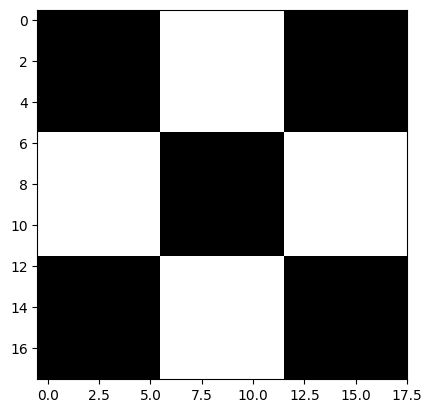

In [ ]:
# Read image as gray scale.
cb_img = cv2.imread("checkerboard_18x18.png", 0)

# Set color map to gray scale for proper rendering.
plt.imshow(cb_img, cmap="gray")
print(cb_img)
print(type(cb_img))

## Accéder aux Pixels Individuels

Voyons comment accéder à un pixel dans l’image.

Pour accéder à n’importe quel pixel dans une matrice numpy, vous devez utiliser la notation matricielle telle que matrix[r,c], où r est le numéro de la ligne et c est le numéro de la colonne. Notez également que la matrice est indexée à partir de 0.

Par exemple, si vous voulez accéder au premier pixel, vous devez spécifier matrix[0,0]. Voyons cela avec quelques exemples. Nous allons afficher un pixel noir en haut à gauche et un pixel blanc au centre supérieur.

In [ ]:
# print the first pixel of the first black box
print(cb_img[0][0])
# print the first white pixel to the right of the first black box
print(cb_img[0, 6])

0
255


## <font style="color:black">Modifier les pixels d'une image</font>
Nous pouvons modifier les valeurs d'intensité des pixels de la même manière que celle décrite ci-dessus.

[[  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0 255 255   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0 255 255   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0

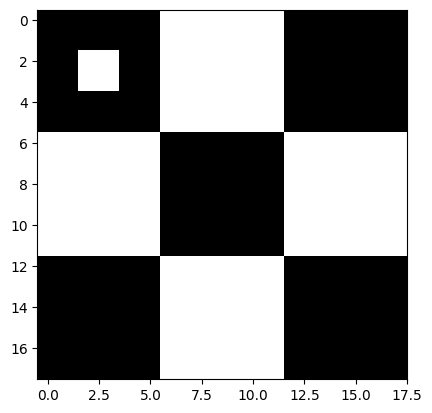

In [ ]:
cb_img_copy = cb_img.copy()
cb_img_copy[2, 2] = 255
cb_img_copy[2, 3] = 255
cb_img_copy[3, 2] = 255
cb_img_copy[3, 3] = 255

# Same as above
# cb_img_copy[2:3,2:3] = 200

plt.imshow(cb_img_copy, cmap="gray")
print(cb_img_copy)

# Croper des images

Recadrer une image est simplement réalisé en sélectionnant une région spécifique (en pixels) de l’image.

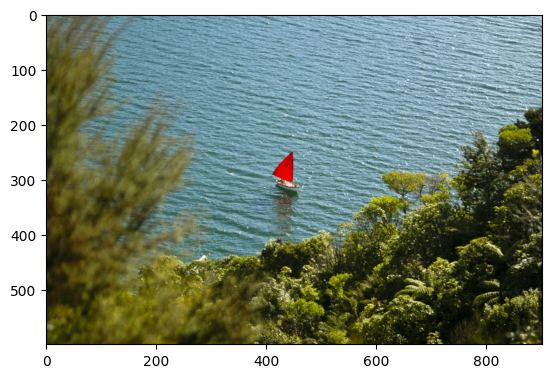

In [ ]:
img_NZ_bgr = cv2.imread("New_Zealand_Boat.jpg", cv2.IMREAD_COLOR)
img_NZ_rgb = img_NZ_bgr[:, :, ::-1]

plt.imshow(img_NZ_rgb)

###Croper la region centrale de l'image

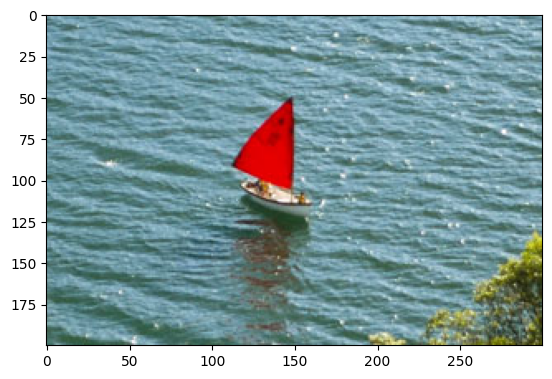

In [ ]:
cropped_region = img_NZ_rgb[200:400, 300:600]
plt.imshow(cropped_region)

In [ ]:
type(img_NZ_rgb)

numpy.ndarray

In [ ]:
img = cv2.imread("./New_Zealand_Boat.jpg")

In [ ]:
img.shape

(600, 903, 3)

array([[[109, 115,  89],
        [105, 113,  89],
        [109, 117,  94],
        ...,
        [163, 191, 212],
        [150, 179, 195],
        [135, 165, 175]],

       [[106, 112,  86],
        [105, 113,  89],
        [110, 118,  95],
        ...,
        [146, 174, 195],
        [138, 167, 183],
        [135, 165, 175]],

       [[106, 112,  86],
        [109, 114,  91],
        [112, 120,  97],
        ...,
        [137, 164, 181],
        [128, 156, 170],
        [136, 164, 175]],

       ...,

       [[ 57,  52,  10],
        [ 56,  51,   9],
        [ 56,  53,  10],
        ...,
        [ 47,  49,  12],
        [ 47,  46,  16],
        [ 53,  50,  15]],

       [[ 56,  53,  12],
        [ 55,  52,  11],
        [ 54,  51,  10],
        ...,
        [ 43,  43,  17],
        [ 45,  43,  22],
        [ 45,  42,  11]],

       [[ 57,  53,  15],
        [ 55,  51,  13],
        [ 53,  49,  11],
        ...,
        [ 40,  40,  16],
        [ 46,  44,  23],
        [ 41,  38,   5]]], dtype=uint8)
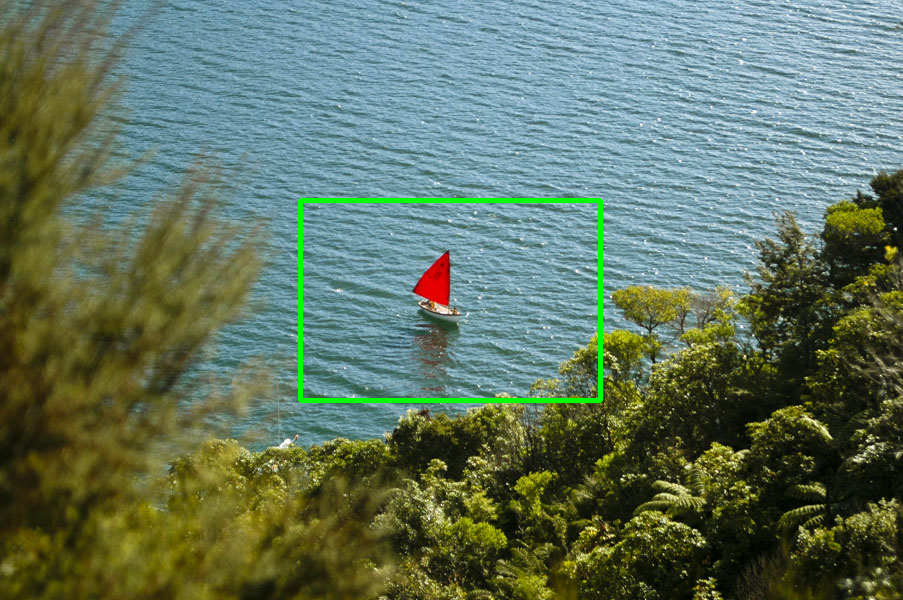

In [ ]:
img = cv2.rectangle(img, (300, 200), (600, 400), color=(0,255,0), thickness=4)
cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Modifier la taille d'une image

La fonction **`resize`** modifie la taille de l'image `src` vers la taille spécifié.

### <font style="color:rgb(8,133,37)">Syntaxe</font>

``` python
dst = resize( src, dsize[, dst[, fx[, fy[, interpolation]]]] )
```

`dst`: image d'output; elle a pour taille dsize ou la taille calculée de src.size(), fx, et fy; le type de dst est le même que le type de src.

La fonction a **2 arguments requis**:
    
1. `src`: image d'entrée

2. `dsize`: taille de l'image de sortie

Arguments souvent inclus:

1. `fx`: Facteur de scaling horizontal

2. `fy`: Facteur de scaling vertical

### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>

**`resize()`**: <a href="https://docs.opencv.org/4.5.0/da/d54/group__imgproc__transform.html#ga47a974309e9102f5f08231edc7e7529d" target="_blank">Documentation link</a>

### Méthode 1: Modifier la taille d'une image avec les facteurs de scaling fx et fy


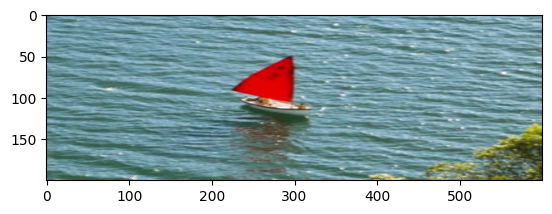

In [ ]:
resized_cropped_region_2x = cv2.resize(cropped_region, None, fx=2, fy=1)
plt.imshow(resized_cropped_region_2x)

In [ ]:
# (200, 300)
resized_cropped_region_2x.shape

(200, 600, 3)

### Méthode 2: Spécifier la taille exacte de l'image d'output

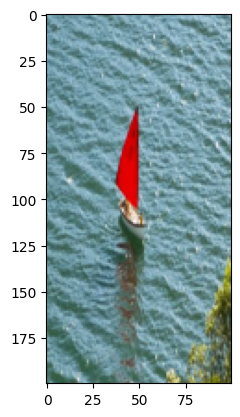

In [ ]:
desired_width = 100
desired_height = 200
dim = (desired_width, desired_height)

# Resize background image to sae size as logo image
resized_cropped_region = cv2.resize(cropped_region, dsize=dim, interpolation=cv2.INTER_AREA)
plt.imshow(resized_cropped_region)

### Modifier la taille en modifiant l'aspect ratio

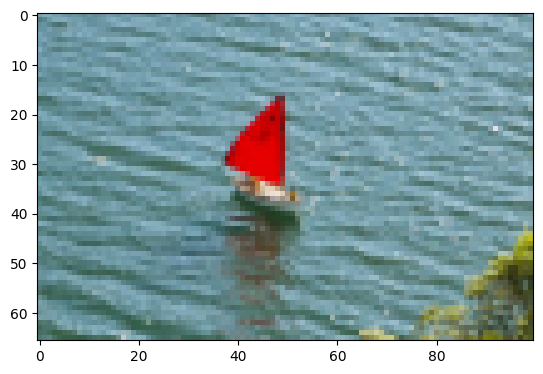

In [ ]:
# Method 2: Using 'dsize'
desired_width = 100
aspect_ratio = desired_width / cropped_region.shape[1]
desired_height = int(cropped_region.shape[0] * aspect_ratio)
dim = (desired_width, desired_height)

# Resize image
resized_cropped_region = cv2.resize(cropped_region, dsize=dim, interpolation=cv2.INTER_AREA)
plt.imshow(resized_cropped_region)

### Affichage de l'image croppée aprés modification de la taille

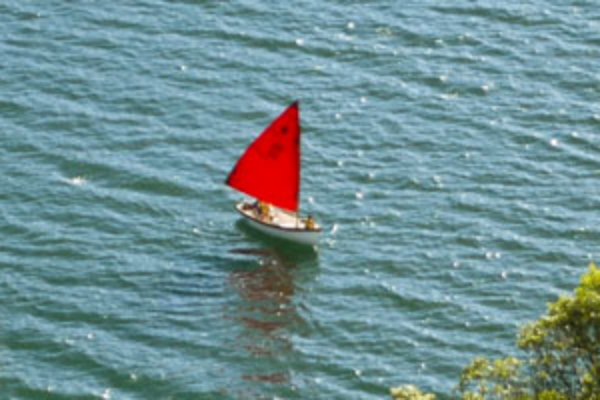

In [ ]:
# Swap channel order
resized_cropped_region_2x = resized_cropped_region_2x[:, :, ::-1]

# Save resized image to disk
cv2.imwrite("resized_cropped_region_2x.png", resized_cropped_region_2x)

# Display the cropped and resized image
Image(filename="resized_cropped_region_2x.png")

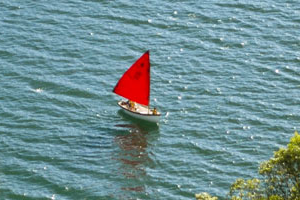

In [ ]:
# Swap channel order
cropped_region = cropped_region[:, :, ::-1]

# Save cropped 'region'
cv2.imwrite("cropped_region.png", cropped_region)

# Display the cropped and resized image
Image(filename="cropped_region.png")

# Retourner une image


La fonction flip inverse le tableau de l’une des trois manières suivantes (les indices de lignes et de colonnes commencent à 0) :

### <font style="color:rgb(8,133,37)">Function Syntax </font>
``` python
dst = cv.flip( src, flipCode )
```

La fonction a **2 arguments requis**:

1. `src`: l'image d'input
2. `flipCode`: un indicateur pour spécifier comment inverser le tableau ; 0 signifie une inversion autour de l’axe x et une valeur positive (par exemple, 1) signifie une inversion autour de l’axe y. Une valeur négative (par exemple, -1) signifie une inversion autour des deux axes.

### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>

**`flip`**: <a href="https://docs.opencv.org/4.5.0/d2/de8/group__core__array.html#gaca7be533e3dac7feb70fc60635adf441" target="_blank">Documentation link</a>

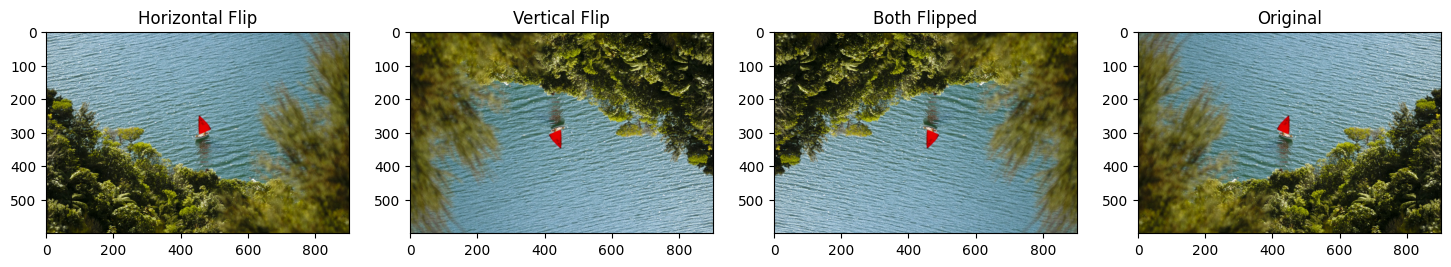

In [ ]:
img_NZ_rgb_flipped_horz = cv2.flip(img_NZ_rgb, 1)
img_NZ_rgb_flipped_vert = cv2.flip(img_NZ_rgb, 0)
img_NZ_rgb_flipped_both = cv2.flip(img_NZ_rgb, -1)

# Show the images
plt.figure(figsize=(18, 5))
plt.subplot(141);plt.imshow(img_NZ_rgb_flipped_horz);plt.title("Horizontal Flip");
plt.subplot(142);plt.imshow(img_NZ_rgb_flipped_vert);plt.title("Vertical Flip");
plt.subplot(143);plt.imshow(img_NZ_rgb_flipped_both);plt.title("Both Flipped");
plt.subplot(144);plt.imshow(img_NZ_rgb);plt.title("Original");
